# Tipologi kondisi pertumbuhan, pembanding wilayah

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

Angka provinsi dibaca dari tabel notebook kerangka. Gambar dan perbandingan dihitung di sel ini. Kalimantan Timur tidak digabung dengan Kalimantan Utara. Bali tidak digabung dengan NTT. Maluku Utara tidak digabung dengan Maluku hanya karena selang RTS-nya.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "02 Code" / "BKPM" / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")

ROOT = find_root()
OUT = ROOT / "01 Data" / "TFP" / "output" / "tipologi"
NAVY, CYAN, RED, TEAL, CREAM, GRAY, KERTAS = (
    "#0E2440", "#5DD0E6", "#D9042B", "#46A694", "#F2E6CE", "#797F8C", "#ffffff",
)
WARNA_KAT = {
    "A": "#0E2440", "B": "#D9042B", "C": "#0E7C66", "D": "#1A6F8A",
    "E": "#C47B2B", "F": "#6B4C7A", "G": "#8C3A3A", "H": "#3D6B8C",
    "I": "#2F6F4F", "J": "#A33B73",
}
GARIS = [
    "#0E2440", "#D9042B", "#0E7C66", "#C47B2B", "#6B4C7A", "#1A6F8A",
    "#A33B73", "#3D6B8C", "#8A6A32", "#3E5C76", "#B85C38", "#2C6E49",
]
KELOMPOK = [
    ("Pertanian", "#E4D3A8"), ("Pertambangan", "#D9042B"), ("Industri", "#0E2440"),
    ("Utilitas dan konstruksi", "#46A694"), ("Jasa", "#5DD0E6"),
]
HURUF = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "MN", "O", "P", "Q", "RSTU"]
JASA_RINCI = [
    ("Perdagangan", ["G"]), ("Transportasi", ["H"]), ("Akomodasi dan makan", ["I"]),
    ("Jasa lain", ["J", "K", "L", "MN", "O", "P", "Q", "RSTU"]),
]
CMAP = LinearSegmentedColormap.from_list("z", ["#8C3A3A", "#F7F1E8", "#0E2440"])
plt.rcParams.update({
    "figure.facecolor": KERTAS, "axes.facecolor": KERTAS, "axes.edgecolor": GRAY,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titlecolor": NAVY, "axes.labelcolor": NAVY,
    "xtick.color": NAVY, "ytick.color": NAVY, "text.color": NAVY,
    "axes.unicode_minus": False, "legend.frameon": False,
})

def simpan(fig, name):
    path = OUT / name
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor=KERTAS)
    print(path.relative_to(ROOT))
    plt.show()
    plt.close(fig)

def bersih(ax, grid="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis=grid)
    if grid == "y":
        ax.grid(axis="x", visible=False)
    elif grid == "x":
        ax.grid(axis="y", visible=False)

def judul(ax, teks):
    ax.set_title(teks, loc="left", color=NAVY, fontsize=12, pad=8)

def koma(x, n=2, tanda=False):
    if pd.isna(x):
        return "—"
    teks = f"{x:+.{n}f}" if tanda else f"{x:.{n}f}"
    return teks.replace(".", ",")

def zscore(series):
    sd = series.std(ddof=0)
    if sd == 0 or np.isnan(sd):
        return series * 0
    return (series - series.mean()) / sd

prov = pd.read_csv(OUT / "tipologi_prov.csv")
panel = pd.read_csv(OUT / "tipologi_panel.csv")
kel = pd.read_csv(OUT / "tipologi_kelompok.csv")
for df, kolom in ((prov, "code"), (panel, "Code_Prov"), (kel, "Code_Prov")):
    df[kolom] = df[kolom].astype(int)
    if "Year" in df.columns:
        df["Year"] = df["Year"].astype(int)
SHORT = dict(zip(prov.code, prov.short))

# Pembanding nasional dihitung ulang dari panel, bukan disalin sebagai angka jadi.
d = panel[panel.Year.between(2017, 2024)].copy()
X = []
for col in ("log_Y", "log_K", "log_L"):
    X.append(
        d[col]
        - d.groupby("Code_Prov")[col].transform("mean")
        - d.groupby("Year")[col].transform("mean")
        + d[col].mean()
    )
b_fe, *_ = np.linalg.lstsq(np.column_stack(X[1:]), X[0], rcond=None)
rts_fe = float(b_fe.sum())
print(f"FE dua arah  b1 {b_fe[0]:.3f}  b2 {b_fe[1]:.3f}  jumlah {rts_fe:.3f}")

# Pangsa jasa dihitung terhadap seluruh tenaga kerja, bukan terhadap jumlah pekerja jasa saja.
sek = pd.read_excel(ROOT / "01 Data/TFP/output/konstruksi/TFP Provinsi 2017-2025.xlsx", sheet_name="sektor")
sek["Code_Prov"] = sek.Code_Prov.astype(int)
sek["Year"] = sek.Year.astype(int)
sek = sek[sek.Year.between(2017, 2024)].copy()
bagian = []
for nama, huruf in JASA_RINCI:
    bagian.append(pd.DataFrame({
        "Code_Prov": sek.Code_Prov.to_numpy(),
        "Year": sek.Year.to_numpy(),
        "kelompok": nama,
        "va": sek[[f"{h}_ADHK" for h in huruf]].sum(axis=1).to_numpy(),
        "tk": sek[[f"{h}_TenagaKerja" for h in huruf]].sum(axis=1).to_numpy(),
    }))
jasa = pd.concat(bagian, ignore_index=True)
tk_semua = sek[[f"{h}_TenagaKerja" for h in HURUF]].sum(axis=1)
jasa = jasa.merge(
    pd.DataFrame({"Code_Prov": sek.Code_Prov, "Year": sek.Year, "tk_semua": tk_semua.to_numpy()}),
    on=["Code_Prov", "Year"],
)
jasa["share_tk_semua"] = jasa.tk / jasa.tk_semua
jasa["lp"] = np.where(jasa.tk > 0, jasa.va * 1000 / jasa.tk, np.nan)


FE dua arah  b1 0.387  b2 0.193  jumlah 0.580


In [2]:
def trajektori(codes, fname, judul_teks):
    fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.8), sharex=True, layout="constrained")
    potong = panel[panel.Year.between(2017, 2024)]
    for ax, col, nama in zip(axes, ["logtfp_it", "logtfp_it_crs"], ["Residual DRS", "Residual CRS"]):
        for i, code in enumerate(codes):
            g = potong[potong.Code_Prov == code].sort_values("Year")
            ax.plot(g.Year, g[col], color=GARIS[i % len(GARIS)], lw=2, marker="o", ms=3.5, label=SHORT[code])
        ax.set_xticks([2017, 2019, 2021, 2024])
        ax.set_ylabel("log residual")
        judul(ax, nama)
        bersih(ax)
    pegangan, lab = axes[0].get_legend_handles_labels()
    fig.legend(pegangan, lab, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.16), fontsize=8)
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def komposisi(codes, fname, judul_teks):
    df = prov.set_index("code")
    kolom = ["tk_A", "tk_B", "tk_C", "tk_def", "tk_jasa"]
    fig, ax = plt.subplots(figsize=(10.4, 1.15 * len(codes) + 1.6), layout="constrained")
    ypos, ylabels = [], []
    for i, code in enumerate(codes):
        r = df.loc[code]
        for geser, pakai_tk, tag in ((0.0, True, "Tenaga kerja"), (0.72, False, "Nilai tambah")):
            kiri, y = 0, i * 2.15 + geser
            for j, nama_warna in enumerate(KELOMPOK):
                nama, warna = nama_warna
                kunci = kolom[j] if pakai_tk else kolom[j].replace("tk_", "va_")
                nilai = 100 * r[kunci]
                ax.barh(y, nilai, left=kiri, height=0.62, color=warna)
                kiri += nilai
            ypos.append(y)
            ylabels.append(f"{SHORT[code]}  {tag}" if pakai_tk else "Nilai tambah")
    ax.set_yticks(ypos)
    ax.set_yticklabels(ylabels, fontsize=8)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Persen, rata-rata 2017–2024")
    ax.invert_yaxis()
    bersih(ax, grid="x")
    judul(ax, judul_teks)
    ax.legend(handles=[Patch(color=w, label=n) for n, w in KELOMPOK], ncol=3, fontsize=8,
              loc="upper center", bbox_to_anchor=(0.5, -0.16))
    simpan(fig, fname)

def indeks_input(codes, fname, judul_teks):
    fig, axes = plt.subplots(2, 2, figsize=(10.6, 7.2), sharex=True, layout="constrained")
    potong = panel[panel.Year.between(2017, 2024)]
    spes = [
        ("pdrb_adhk", "Output riil, 2017 = 100", True),
        ("pmtb_adhk", "Arus PMTB riil, 2017 = 100", True),
        ("labours_total", "Tenaga kerja, 2017 = 100", True),
        ("logtfp_it_crs", "Residual CRS, selisih dari 2017", False),
    ]
    for ax, (col, nama, sebagai_indeks) in zip(axes.ravel(), spes):
        for i, code in enumerate(codes):
            g = potong[potong.Code_Prov == code].sort_values("Year")
            y = 100 * g[col] / g[col].iloc[0] if sebagai_indeks else g[col] - g[col].iloc[0]
            ax.plot(g.Year, y, color=GARIS[i % len(GARIS)], lw=2, marker="o", ms=3.2, label=SHORT[code])
        judul(ax, nama)
        bersih(ax)
        ax.set_xticks([2017, 2019, 2021, 2024])
    pegangan, lab = axes[0, 0].get_legend_handles_labels()
    fig.legend(pegangan, lab, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.12), fontsize=8)
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def kontribusi(codes, fname, judul_teks):
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.8), sharey=True, layout="constrained")
    x = np.arange(len(KELOMPOK))
    lebar = 0.8 / len(codes)
    for ax, kolom, nama in zip(axes, ["va", "tk"], ["Kontribusi ke pertumbuhan nilai tambah", "Kontribusi ke pertumbuhan tenaga kerja"]):
        for i, code in enumerate(codes):
            a = kel[(kel.Code_Prov == code) & (kel.Year == 2017)].set_index("kelompok")
            b = kel[(kel.Code_Prov == code) & (kel.Year == 2024)].set_index("kelompok")
            dasar = a[kolom].sum()
            nilai = [(b.loc[n, kolom] - a.loc[n, kolom]) / dasar * 100 for n, _ in KELOMPOK]
            ax.bar(x + i * lebar, nilai, width=lebar * 0.92, color=GARIS[i % len(GARIS)], label=SHORT[code])
        ax.axhline(0, color=GRAY, lw=0.7)
        ax.set_xticks(x + lebar * (len(codes) - 1) / 2)
        ax.set_xticklabels([n for n, _ in KELOMPOK], rotation=20, ha="right", fontsize=8)
        ax.set_ylabel("Poin persentase dari total 2017")
        judul(ax, nama)
        bersih(ax)
    axes[0].legend(fontsize=8)
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def level_tren(sorot, fname, judul_teks, teman=None):
    fig, ax = plt.subplots(figsize=(8.4, 6.4), layout="constrained")
    ax.errorbar(
        100 * prov.tren_crs, prov.tfp_crs,
        xerr=100 * np.vstack([prov.tren_crs - prov.tren_crs_lo, prov.tren_crs_hi - prov.tren_crs]),
        fmt="none", ecolor="#E3E6EA", elinewidth=0.8, zorder=1,
    )
    ax.scatter(100 * prov.tren_crs, prov.tfp_crs, s=28, c="#D5D8DE", zorder=2)
    for code in sorot:
        r = prov.set_index("code").loc[code]
        ax.scatter(100 * r.tren_crs, r.tfp_crs, s=64, c=WARNA_KAT[r.kode_kat], zorder=3)
        ax.annotate(r.short, (100 * r.tren_crs, r.tfp_crs), textcoords="offset points", xytext=(4, 3), fontsize=8, color=WARNA_KAT[r.kode_kat])
    for code in teman or []:
        r = prov.set_index("code").loc[code]
        ax.scatter(100 * r.tren_crs, r.tfp_crs, s=36, facecolors="white", edgecolors=NAVY, zorder=3)
        ax.annotate(r.short, (100 * r.tren_crs, r.tfp_crs), textcoords="offset points", xytext=(4, 3), fontsize=7, color=GRAY)
    ax.axvline(0, color=GRAY, lw=0.7)
    ax.axhline(prov.tfp_crs.median(), color=GRAY, lw=0.7, ls="--")
    ax.set_xlabel("Tren residual CRS, poin log per tahun")
    ax.set_ylabel("Rata-rata log residual CRS")
    judul(ax, judul_teks)
    simpan(fig, fname)

def panah(codes, fname, judul_teks):
    fig, ax = plt.subplots(figsize=(8.2, 6.2), layout="constrained")
    for i, code in enumerate(codes):
        g = panel[panel.Code_Prov == code].set_index("Year")
        x0, x1 = g.loc[2017, "kl"], g.loc[2024, "kl"]
        y0, y1 = g.loc[2017, "yl"], g.loc[2024, "yl"]
        warna = GARIS[i % len(GARIS)]
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", color=warna, lw=1.6))
        ax.scatter([x0, x1], [y0, y1], s=28, color=warna)
        ax.annotate(SHORT[code], (x1, y1), textcoords="offset points", xytext=(5, 4), fontsize=8, color=warna, clip_on=False)
    ax.set_xlabel("Arus PMTB riil per pekerja, juta rupiah")
    ax.set_ylabel("PDRB riil per pekerja, juta rupiah")
    judul(ax, judul_teks)
    simpan(fig, fname)

def level_peringkat(codes, fname, judul_teks):
    # Dua level log tidak disambung. Normalisasinya berbeda, jadi jaraknya bukan selisih produktivitas.
    df = prov.set_index("code").loc[codes].reset_index().sort_values("rank_crs", ascending=False)
    fig, axes = plt.subplots(1, 3, figsize=(11.4, 0.48 * len(codes) + 1.8), sharey=True, layout="constrained")
    axes[0].scatter(df.tfp_drs, df.short, s=36, color=NAVY, zorder=2)
    axes[1].scatter(df.tfp_crs, df.short, s=36, color=CYAN, zorder=2)
    for r in df.itertuples(index=False):
        axes[2].plot([r.rank_drs, r.rank_crs], [r.short, r.short], color=GRAY, lw=1.2, zorder=1)
    axes[2].scatter(df.rank_drs, df.short, s=32, color=NAVY, label="DRS", zorder=2)
    axes[2].scatter(df.rank_crs, df.short, s=32, color=CYAN, label="CRS", zorder=2)
    axes[2].invert_xaxis()
    axes[2].set_xlabel("Peringkat 1 di kanan")
    axes[2].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))
    for ax, nama in zip(axes, ["Level log residual DRS", "Level log residual CRS", "Peringkat"]):
        judul(ax, nama)
        bersih(ax, grid="x")
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def forest(codes, fname, judul_teks):
    df = prov.set_index("code").loc[list(reversed(codes))].reset_index()
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 0.46 * len(codes) + 1.6), sharey=True, layout="constrained")
    y = np.arange(len(df))
    axes[0].hlines(y, df.rts_lo, df.rts_hi, color=NAVY, lw=1.5)
    warna = [TEAL if u == "IRS" else RED if u == "DRS" else GRAY for u in df.uji]
    axes[0].scatter(df.rts, y, c=warna, s=36, zorder=3)
    axes[0].axvline(1, color=GRAY, lw=0.8)
    axes[0].axvline(rts_fe, color=NAVY, lw=0.7, ls="--")
    axes[0].set_yticks(y)
    axes[0].set_yticklabels(df.short)
    axes[0].set_xlabel("RTS dan selang 95%")
    judul(axes[0], "Skala hasil")
    warna_gap = [TEAL if v > 0 else RED if v < 0 else GRAY for v in df.selisih]
    axes[1].barh(y, df.selisih, color=warna_gap, height=0.62)
    axes[1].axvline(0, color=NAVY, lw=0.7)
    axes[1].set_xlabel("Peringkat DRS − peringkat CRS")
    judul(axes[1], "Selisih peringkat")
    for ax in axes:
        bersih(ax, grid="x")
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def primer(codes, fname, judul_teks):
    df = prov.set_index("code").loc[codes]
    fig, axes = plt.subplots(1, 3, figsize=(11.4, 0.48 * len(codes) + 1.8), sharey=True, layout="constrained")
    y = np.arange(len(codes))
    for ax, a, b, nama in (
        (axes[0], "tk_A", "tk_B", "Pangsa tenaga kerja"),
        (axes[1], "va_A", "va_B", "Pangsa nilai tambah"),
        (axes[2], "lp_A", "lp_B", "Nilai tambah per pekerja, 2024"),
    ):
        skala = 100 if a.startswith(("tk", "va")) else 1
        ax.barh(y + 0.16, skala * df[a], height=0.3, color="#E4D3A8", label="Pertanian")
        ax.barh(y - 0.16, skala * df[b], height=0.3, color=RED, label="Pertambangan")
        ax.set_yticks(y)
        ax.set_yticklabels([SHORT[c] for c in codes])
        judul(ax, nama)
        bersih(ax, grid="x")
    axes[0].legend(fontsize=8)
    axes[0].set_xlabel("Persen")
    axes[1].set_xlabel("Persen")
    axes[2].set_xlabel("Juta rupiah")
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def heatmap_kode(codes, kolom, fname, judul_teks):
    df = prov.set_index("code").loc[codes].reset_index()
    zmat, mentah = [], []
    for col, _lab, kali in kolom:
        zmat.append(zscore(prov.set_index("code")[col]).loc[df.code].to_numpy())
        mentah.append((df[col] * kali).to_numpy())
    mat = np.column_stack(zmat)
    teks = np.column_stack(mentah)
    fig, ax = plt.subplots(figsize=(1.15 * len(kolom) + 2.4, 0.55 * len(df) + 1.8), layout="constrained")
    batas = max(2.2, float(np.nanmax(np.abs(mat))))
    im = ax.imshow(mat, cmap=CMAP, vmin=-batas, vmax=batas, aspect="auto")
    ax.set_xticks(range(len(kolom)))
    ax.set_xticklabels([lab for _, lab, _ in kolom], rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(df)))
    ax.set_yticklabels(df.short, fontsize=9)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            tinta = KERTAS if abs(mat[i, j]) > 0.72 * batas else NAVY
            ax.text(j, i, koma(teks[i, j], 1 if abs(teks[i, j]) >= 10 else 2), ha="center", va="center", fontsize=7, color=tinta)
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02, label="z terhadap 34 provinsi")
    judul(ax, judul_teks)
    simpan(fig, fname)

def lp_sektor(codes, fname, judul_teks):
    g = kel[(kel.Code_Prov.isin(codes)) & (kel.Year == 2024)]
    fig, ax = plt.subplots(figsize=(max(10.6, 1.15 * len(codes) + 4), 5.2), layout="constrained")
    x = np.arange(len(KELOMPOK))
    lebar = 0.8 / len(codes)
    for i, code in enumerate(codes):
        sub = g[g.Code_Prov == code].set_index("kelompok")
        ax.bar(x + i * lebar, [sub.loc[n, "lp"] for n, _ in KELOMPOK], width=lebar * 0.92, color=GARIS[i % len(GARIS)], label=SHORT[code])
    ax.set_xticks(x + lebar * (len(codes) - 1) / 2)
    ax.set_xticklabels([n for n, _ in KELOMPOK], rotation=15, ha="right")
    ax.set_ylabel("Juta rupiah per pekerja, 2024")
    judul(ax, judul_teks)
    ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22))
    bersih(ax)
    simpan(fig, fname)

def sekolah(sorot, fname, judul_teks):
    fig, ax = plt.subplots(figsize=(8.6, 6.6), layout="constrained")
    ax.scatter(prov.sekolah, prov.tfp_crs, s=28, c="#D5D8DE", zorder=2)
    for r in prov.itertuples(index=False):
        if r.code in sorot:
            ax.scatter(r.sekolah, r.tfp_crs, s=64, c=WARNA_KAT[r.kode_kat], zorder=3)
            ax.annotate(r.short, (r.sekolah, r.tfp_crs), textcoords="offset points", xytext=(4, 3), fontsize=8, color=WARNA_KAT[r.kode_kat])
    ax.set_xlabel("Rata-rata lama sekolah, tahun")
    ax.set_ylabel("Rata-rata log residual CRS")
    judul(ax, judul_teks)
    simpan(fig, fname)

def konversi(codes, fname, judul_teks):
    fig, axes = plt.subplots(1, 3, figsize=(11.2, 4.6), layout="constrained")
    for ax, x, y, xl, yl in (
        (axes[0], "sekolah", "tpt", "Lama sekolah, tahun", "TPT, persen"),
        (axes[1], "sekolah", "upah24", "Lama sekolah, tahun", "Upah riil 2024, rupiah"),
        (axes[2], "sekolah", "yl24", "Lama sekolah, tahun", "PDRB per pekerja 2024, juta"),
    ):
        ax.scatter(prov[x], prov[y], s=18, c="#D5D8DE", zorder=1)
        for i, code in enumerate(codes):
            r = prov.set_index("code").loc[code]
            ax.scatter(r[x], r[y], s=56, c=GARIS[i % len(GARIS)], zorder=2)
            ax.annotate(SHORT[code], (r[x], r[y]), textcoords="offset points", xytext=(3, 3), fontsize=7)
        ax.set_xlabel(xl)
        ax.set_ylabel(yl)
        bersih(ax)
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def jalur_kecil(pasangan, fname, judul_teks):
    fig, axes = plt.subplots(1, len(pasangan), figsize=(2.6 * len(pasangan) + 0.8, 4.4), sharey=True, layout="constrained")
    potong = panel[panel.Year.between(2017, 2024)]
    for ax, (fokus, teman) in zip(axes, pasangan):
        warna_fokus = WARNA_KAT[prov.set_index("code").loc[fokus, "kode_kat"]]
        urutan = [(fokus, 2.3)] + [(c, 1.2) for c in teman]
        akhir = []
        for code, lw in urutan:
            g = potong[potong.Code_Prov == code].sort_values("Year")
            warna = warna_fokus if code == fokus else GRAY
            ax.plot(g.Year, g.logtfp_it_crs, color=warna, lw=lw)
            akhir.append((code, float(g.logtfp_it_crs.iloc[-1]), warna))
        akhir.sort(key=lambda item: -item[1])
        for i, (code, nilai, warna) in enumerate(akhir):
            geser = 0 if i == 0 else (-7 if i == 1 else 7)
            ax.annotate(SHORT[code], (2024, nilai), textcoords="offset points", xytext=(3, geser), fontsize=6.5, color=warna, va="center", annotation_clip=False)
        ax.set_title(SHORT[fokus], loc="left", fontsize=11, color=NAVY)
        ax.set_xticks([2017, 2020, 2024])
        ax.set_xlim(2016.6, 2026.4)
        bersih(ax)
    axes[0].set_ylabel("Log residual CRS")
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def gambar_jasa(codes, fname, judul_teks):
    g = jasa[(jasa.Code_Prov.isin(codes)) & (jasa.Year == 2024)]
    kelompok = ["Perdagangan", "Transportasi", "Akomodasi dan makan", "Jasa lain"]
    fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.8), layout="constrained")
    x = np.arange(len(kelompok))
    lebar = 0.8 / len(codes)
    for ax, col, nama in (
        (axes[0], "share_tk_semua", "Pangsa dari seluruh tenaga kerja"),
        (axes[1], "lp", "Nilai tambah per pekerja"),
    ):
        for i, code in enumerate(codes):
            sub = g[g.Code_Prov == code].set_index("kelompok")
            nilai = [100 * sub.loc[k, col] if col.startswith("share") else sub.loc[k, col] for k in kelompok]
            ax.bar(x + i * lebar, nilai, width=lebar * 0.92, color=GARIS[i % len(GARIS)], label=SHORT[code])
        ax.set_xticks(x + lebar * (len(codes) - 1) / 2)
        ax.set_xticklabels(kelompok, rotation=15, ha="right", fontsize=8)
        judul(ax, nama)
        bersih(ax)
    axes[0].legend(fontsize=8)
    axes[0].set_ylabel("Persen")
    axes[1].set_ylabel("Juta rupiah, 2024")
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def profil_batang(codes, fname, judul_teks):
    df = prov.set_index("code")
    fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.6), layout="constrained")
    x = np.arange(len(codes))
    lebar = 0.2
    for i, (col, lab) in enumerate([("pil_pendidikan", "Pendidikan"), ("pil_equity", "Ekuitas"), ("pil_konektivitas", "Konektivitas")]):
        axes[0].bar(x + (i - 1) * lebar, zscore(prov.set_index("code")[col]).loc[codes], width=lebar * 0.92, label=lab, color=GARIS[i])
    axes[0].axhline(0, color=GRAY, lw=0.7)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels([SHORT[c] for c in codes])
    axes[0].set_ylabel("z terhadap 34 provinsi")
    judul(axes[0], "Pilar, lebih tinggi lebih kuat")
    axes[0].legend(fontsize=8)
    for i, (col, lab) in enumerate([("tpt", "TPT"), ("p0_24", "Kemiskinan 2024")]):
        axes[1].bar(x + (i - 0.5) * 0.35, df.loc[codes, col], width=0.32, label=lab, color=GARIS[i + 3])
    axes[1].set_xticks(x)
    axes[1].set_xticklabels([SHORT[c] for c in codes])
    axes[1].set_ylabel("Persen")
    judul(axes[1], "Pengangguran dan kemiskinan, satuan asli")
    axes[1].legend(fontsize=8)
    for ax in axes:
        bersih(ax)
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)


## Kalimantan

Lima provinsi. Warna mengikuti kelompok nasional, supaya C dan D tetap terpisah. Garis putus-putus adalah jumlah elastisitas FE nasional.


  short kode_kat      uji      rts    rts_lo   rts_hi  rank_drs  rank_crs     tk_B     va_B
 Kaltim        C memuat 1 0.796474  0.573124 1.019823         4         2 0.082615 0.470472
Kaltara        D memuat 1 1.358682  0.500598 2.216765        23         4 0.032881 0.268410
 Kalsel        I memuat 1 0.485589 -0.527251 1.498430        16        11 0.041369 0.247911
Kalteng        I memuat 1 1.010916 -0.308716 2.330548        25        20 0.075144 0.149655
 Kalbar        F memuat 1 1.145600  0.719346 1.571853        20        26 0.027528 0.050551
01 Data/TFP/output/tipologi/tip_W_kalimantan.png


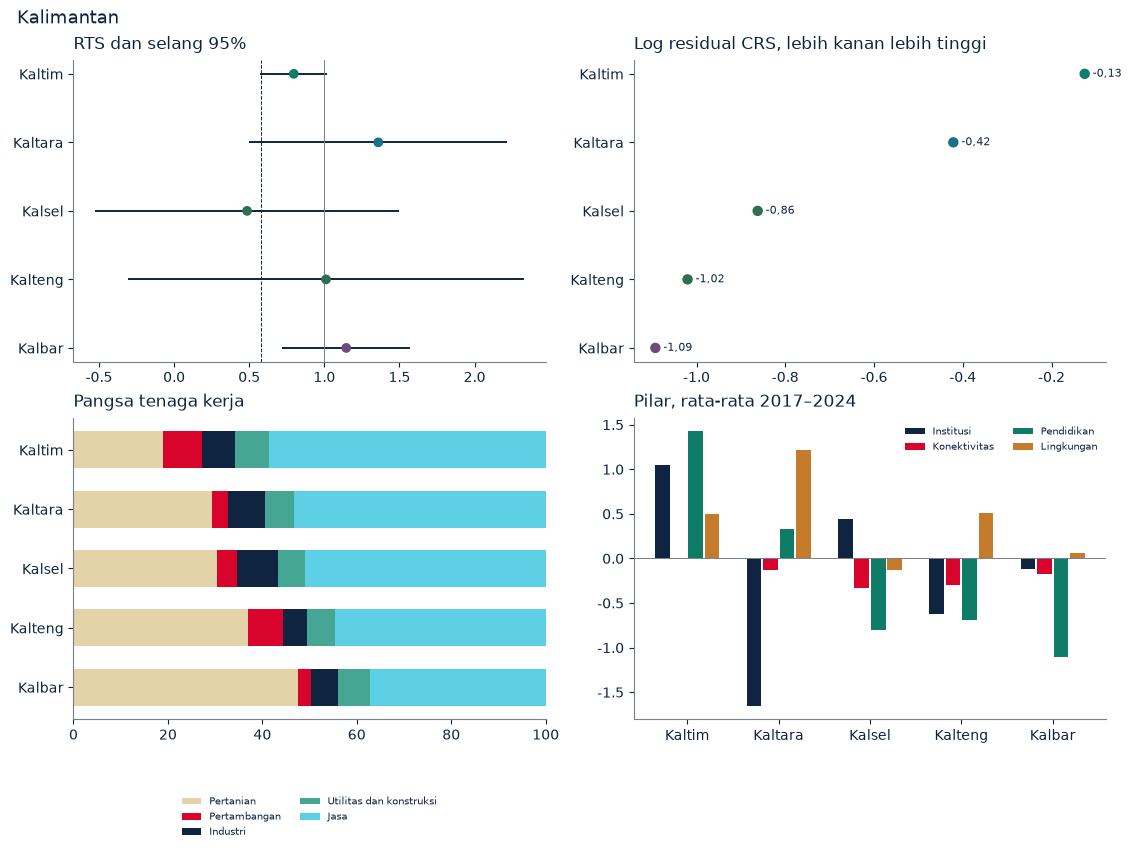

In [3]:
kode = [64, 65, 63, 62, 61]
df = prov.set_index("code").loc[kode].reset_index()
print(df[["short", "kode_kat", "uji", "rts", "rts_lo", "rts_hi", "rank_drs", "rank_crs", "tk_B", "va_B"]].to_string(index=False))
fig, axes = plt.subplots(2, 2, figsize=(11.2, 8.4), layout="constrained")
y = np.arange(len(df))[::-1]
axes[0, 0].hlines(y, df.rts_lo, df.rts_hi, color=NAVY, lw=1.4)
axes[0, 0].scatter(df.rts, y, c=[WARNA_KAT[k] for k in df.kode_kat], s=36, zorder=3)
axes[0, 0].axvline(1, color=GRAY, lw=0.7)
axes[0, 0].axvline(rts_fe, color=NAVY, lw=0.7, ls="--")
axes[0, 0].set_yticks(y)
axes[0, 0].set_yticklabels(df.short)
judul(axes[0, 0], "RTS dan selang 95%")
axes[0, 1].scatter(df.tfp_crs, y, s=42, c=[WARNA_KAT[k] for k in df.kode_kat], zorder=3)
for yi, nilai in zip(y, df.tfp_crs):
    axes[0, 1].text(nilai, yi, f"  {nilai:.2f}".replace(".", ","), va="center", fontsize=8, color=NAVY)
axes[0, 1].set_yticks(y)
axes[0, 1].set_yticklabels(df.short)
judul(axes[0, 1], "Log residual CRS, lebih kanan lebih tinggi")
kiri = np.zeros(len(kode))
for (nama, warna), kol in zip(KELOMPOK, ["tk_A", "tk_B", "tk_C", "tk_def", "tk_jasa"]):
    axes[1, 0].barh(y, 100 * df[kol], left=kiri, color=warna, height=0.62, label=nama)
    kiri = kiri + 100 * df[kol].to_numpy()
axes[1, 0].set_yticks(y)
axes[1, 0].set_yticklabels(df.short)
axes[1, 0].set_xlim(0, 100)
judul(axes[1, 0], "Pangsa tenaga kerja")
axes[1, 0].legend(fontsize=7, loc="lower center", bbox_to_anchor=(0.5, -0.42), ncol=2)
x = np.arange(len(kode))
for i, (col, lab) in enumerate([("pil_institusi", "Institusi"), ("pil_konektivitas", "Konektivitas"), ("pil_pendidikan", "Pendidikan"), ("pil_lingkungan", "Lingkungan")]):
    axes[1, 1].bar(x + (i - 1.5) * 0.18, df[col], width=0.16, label=lab, color=GARIS[i])
axes[1, 1].axhline(0, color=GRAY, lw=0.7)
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(df.short)
judul(axes[1, 1], "Pilar, rata-rata 2017–2024")
axes[1, 1].legend(fontsize=7, ncol=2)
for ax in axes.ravel():
    bersih(ax, grid="x")
fig.suptitle("Kalimantan", x=0.01, ha="left", color=NAVY, fontsize=13)
simpan(fig, "tip_W_kalimantan.png")


## Jawa

Enam provinsi, termasuk DI Yogyakarta. Level log dan peringkat tidak dijadikan satu selisih. Nilai tambah per pekerja memisahkan skala dari produktivitas di dalam sektor.


        short kode_kat  rank_drs  rank_crs  selisih        yl24   sekolah
code                                                                     
31    Jakarta        A         1         1        0  442.892979  11.21000
36     Banten        E         8        13       -5   97.172650   8.90250
32      Jabar        E         3        12       -9   77.769785   8.53750
33     Jateng        E         5        23      -18   60.549729   7.69375
34        DIY        H        22        24       -2   64.003728   9.57250
35      Jatim        E         2         9       -7   91.725177   7.80000
01 Data/TFP/output/tipologi/tip_W_jawa_level.png


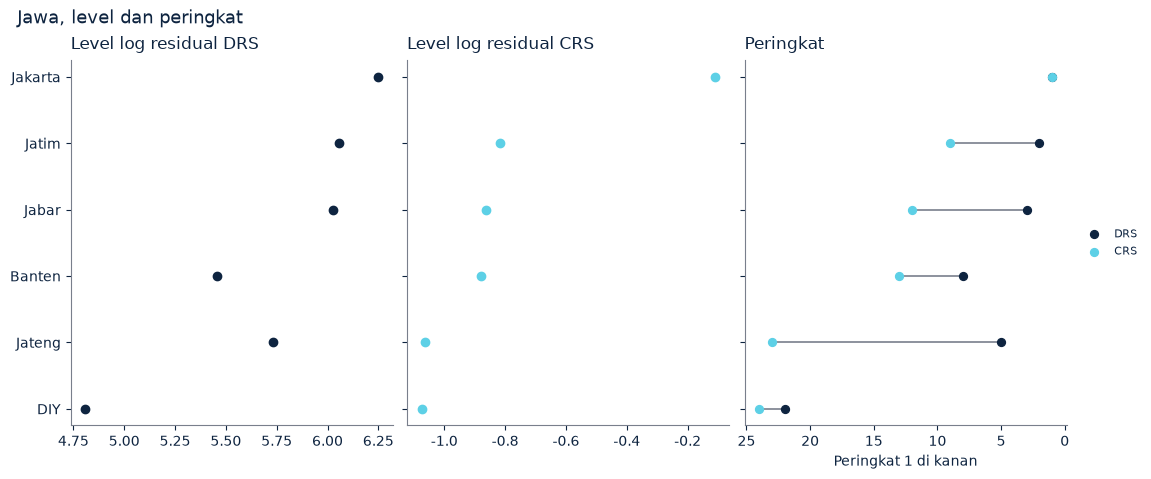

01 Data/TFP/output/tipologi/tip_W_jawa_sektor.png


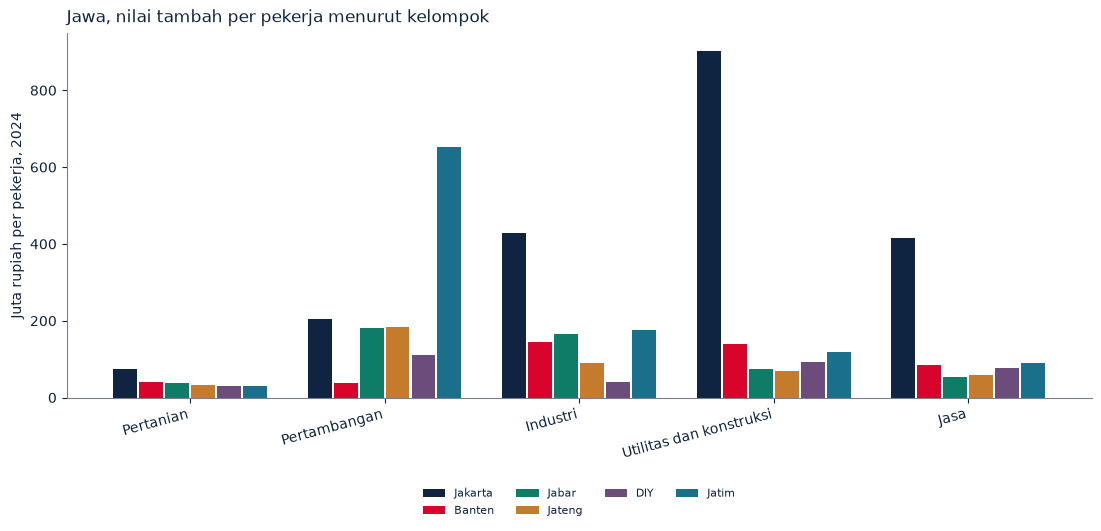

01 Data/TFP/output/tipologi/tip_W_jawa_pilar.png


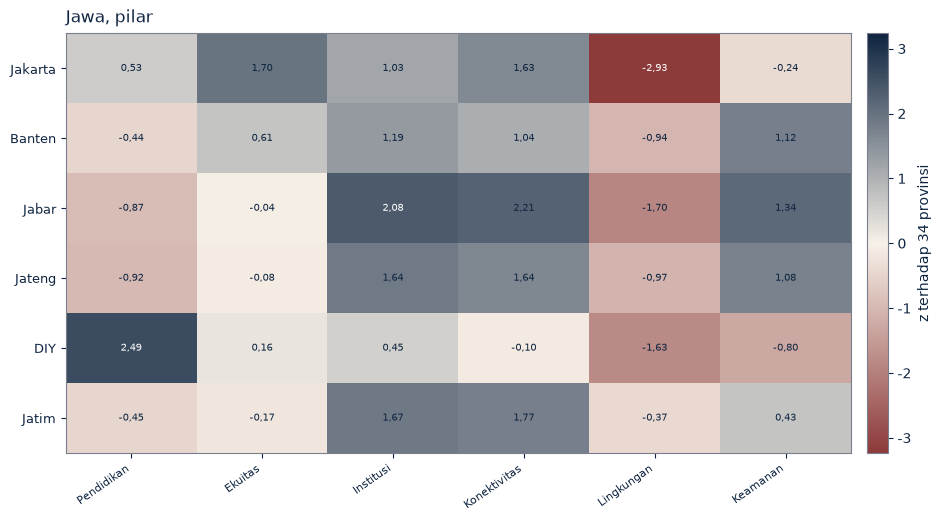

In [4]:
kode = [31, 36, 32, 33, 34, 35]
print(prov.set_index("code").loc[kode, ["short", "kode_kat", "rank_drs", "rank_crs", "selisih", "yl24", "sekolah"]].to_string())
level_peringkat(kode, "tip_W_jawa_level.png", "Jawa, level dan peringkat")
lp_sektor(kode, "tip_W_jawa_sektor.png", "Jawa, nilai tambah per pekerja menurut kelompok")
heatmap_kode(
    kode,
    [(c, lab, 1) for c, lab in [
        ("pil_pendidikan", "Pendidikan"), ("pil_equity", "Ekuitas"), ("pil_institusi", "Institusi"),
        ("pil_konektivitas", "Konektivitas"), ("pil_lingkungan", "Lingkungan"), ("pil_keamanan", "Keamanan"),
    ]],
    "tip_W_jawa_pilar.png", "Jawa, pilar",
)


## Sulawesi

Enam provinsi. Jalur mengindeks output, arus PMTB, dan tenaga kerja pada 2017. Residual CRS digambar sebagai selisih dari 2017, dalam poin log, bukan indeks.


          short kode_kat       uji       rts  rank_crs  tren_crs  tk_primer
code                                                                       
71        Sulut        I       IRS  1.507110        16  0.016856   0.269476
72      Sulteng        B  memuat 1  3.059816        15  0.038391   0.429550
73       Sulsel        E       IRS  1.188240        19  0.007366   0.365575
74       Sultra        I       IRS  1.548680        22  0.016397   0.353689
75    Gorontalo        J       IRS  1.507848        29  0.012189   0.326012
76       Sulbar        J  memuat 1  1.183985        28  0.003271   0.486576
01 Data/TFP/output/tipologi/tip_W_sulawesi_jalur.png


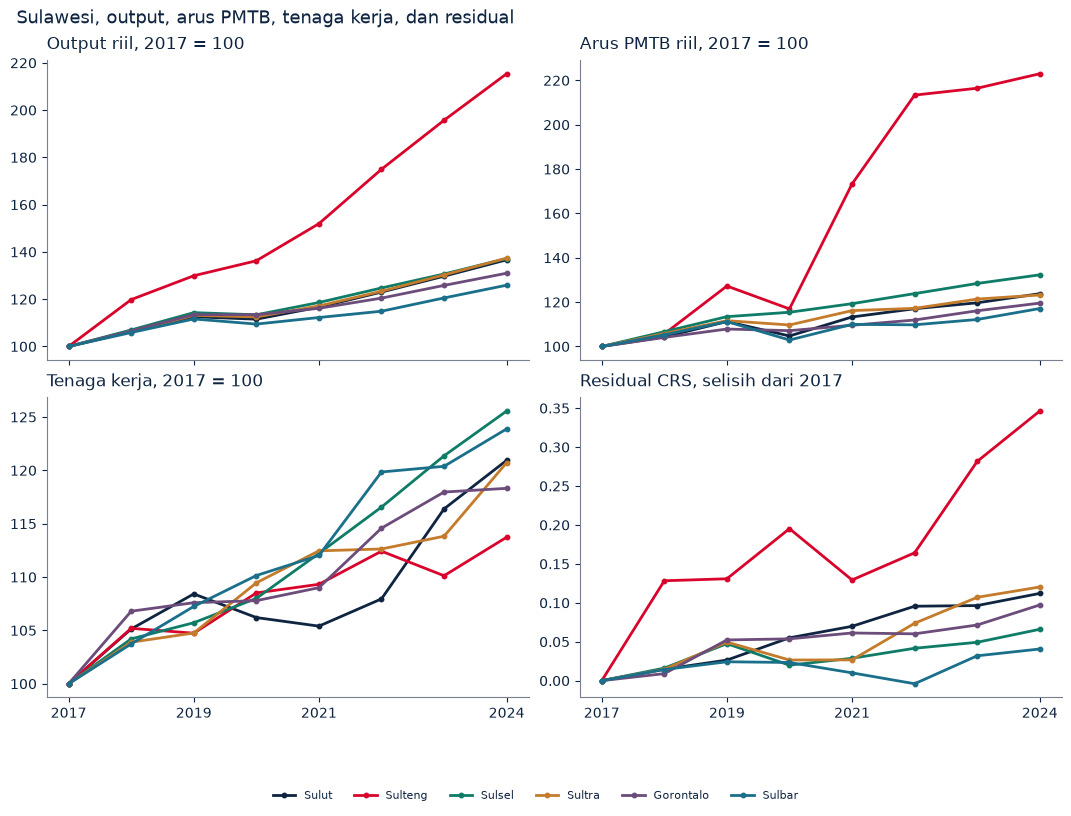

01 Data/TFP/output/tipologi/tip_W_sulawesi_tk.png


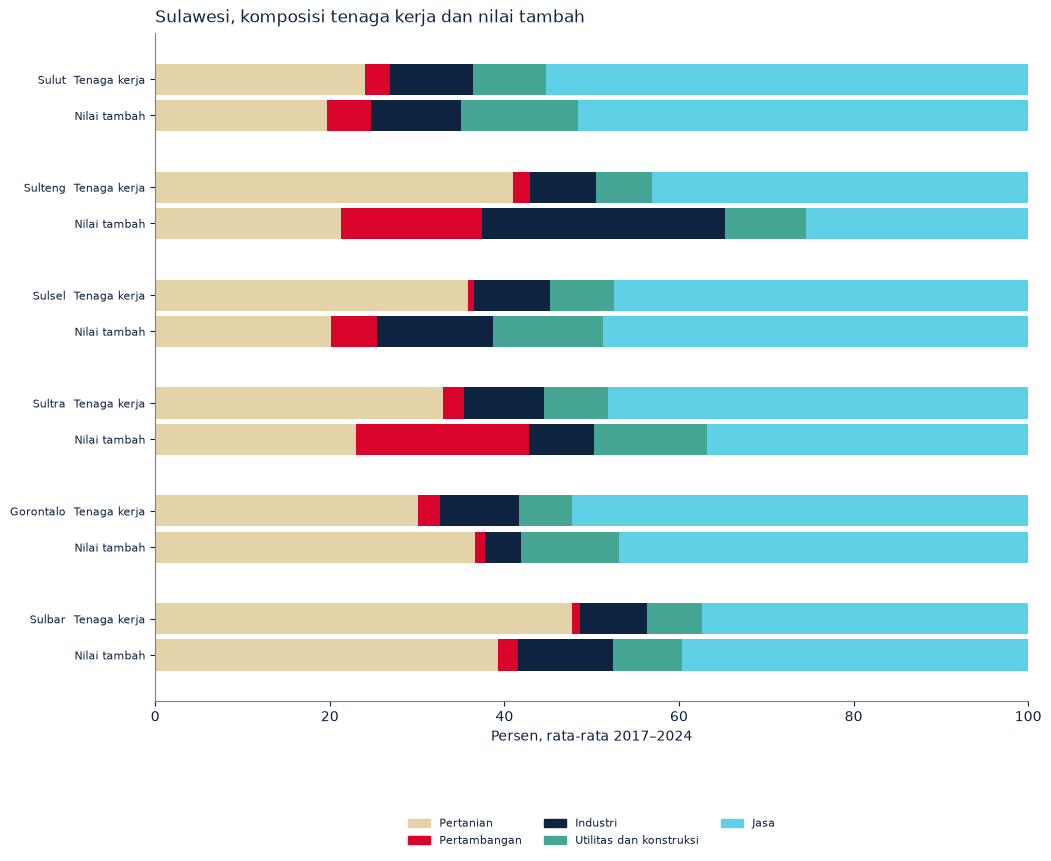

In [5]:
kode = [71, 72, 73, 74, 75, 76]
print(prov.set_index("code").loc[kode, ["short", "kode_kat", "uji", "rts", "rank_crs", "tren_crs", "tk_primer"]].to_string())
indeks_input(kode, "tip_W_sulawesi_jalur.png", "Sulawesi, output, arus PMTB, tenaga kerja, dan residual")
komposisi(kode, "tip_W_sulawesi_tk.png", "Sulawesi, komposisi tenaga kerja dan nilai tambah")


## Sumatera, Kepulauan Riau, dan Bangka Belitung

Angka di dalam sel adalah nilai asli. Warna adalah z terhadap 34 provinsi, bukan terhadap pulau ini saja.


         short kode_kat  tfp_crs    rts  selisih
code                                            
11        Aceh        H   -1.118  1.474       -6
12       Sumut        E   -0.881  1.062       -7
13      Sumbar        F   -0.946  1.124       -4
14        Riau        A   -0.481  0.848        1
15       Jambi        I   -0.700  1.357        4
16      Sumsel        E   -0.941  3.109       -8
17    Bengkulu        J   -1.338  1.400       -2
18     Lampung        F   -1.086  1.254      -13
19       Babel        D   -0.769  1.187       18
21       Kepri        C   -0.559  0.991        7
01 Data/TFP/output/tipologi/tip_W_sumatra.png


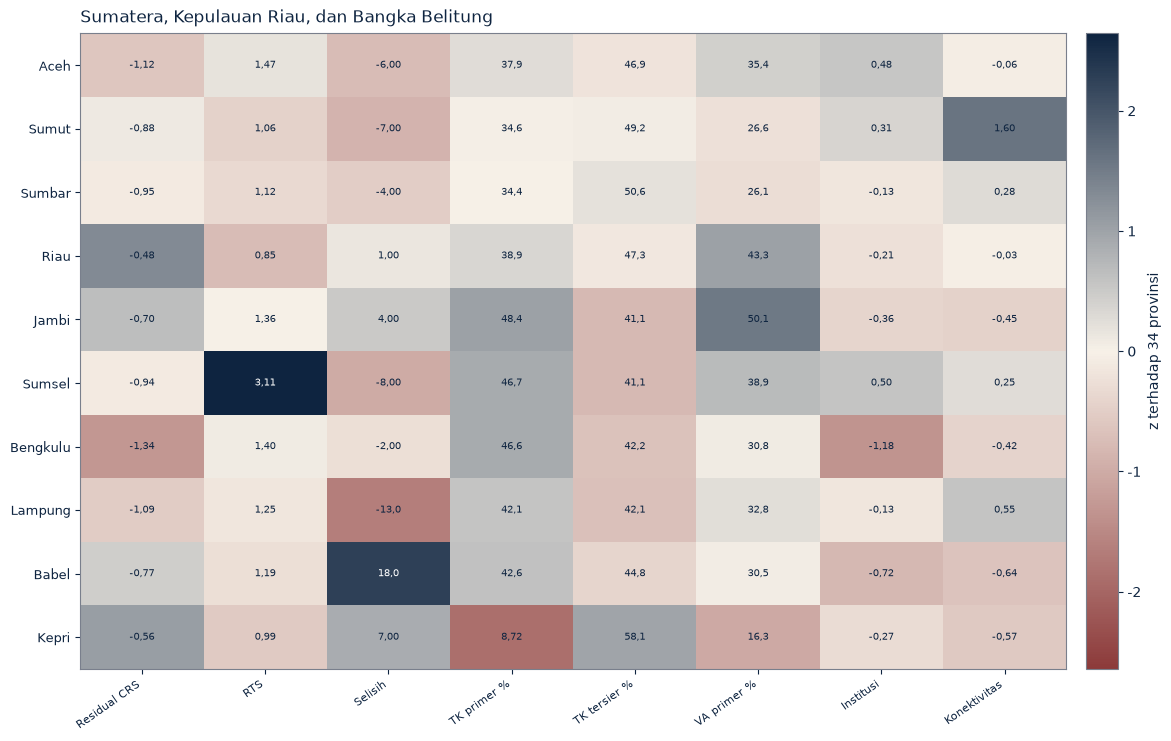

In [6]:
kode = [11, 12, 13, 14, 15, 16, 17, 18, 19, 21]
print(prov.set_index("code").loc[kode, ["short", "kode_kat", "tfp_crs", "rts", "selisih"]].round(3).to_string())
heatmap_kode(
    kode,
    [
        ("tfp_crs", "Residual CRS", 1), ("rts", "RTS", 1), ("selisih", "Selisih", 1),
        ("tk_primer", "TK primer %", 100), ("tk_tersier", "TK tersier %", 100),
        ("va_primer", "VA primer %", 100),
        ("pil_institusi", "Institusi", 1), ("pil_konektivitas", "Konektivitas", 1),
    ],
    "tip_W_sumatra.png", "Sumatera, Kepulauan Riau, dan Bangka Belitung",
)


## Bali dan Nusa Tenggara

Nilai tambah per pekerja dan kualitas kerja untuk tiga provinsi. Rincian jasa membandingkan Bali dengan NTB dan DI Yogyakarta, karena pembanding struktur Bali bukan NTT.


     short kode_kat  tk_tersier  tk_primer      tpt        upah24  p0_24
code                                                                    
51    Bali        J    0.593655   0.182234  3.09125  1.608384e+06   4.00
52     NTB        F    0.465954   0.340498  3.22875  1.113827e+06  12.91
53     NTT        F    0.345568   0.507033  3.37625  7.509402e+05  19.48
01 Data/TFP/output/tipologi/tip_W_balinusra_sektor.png


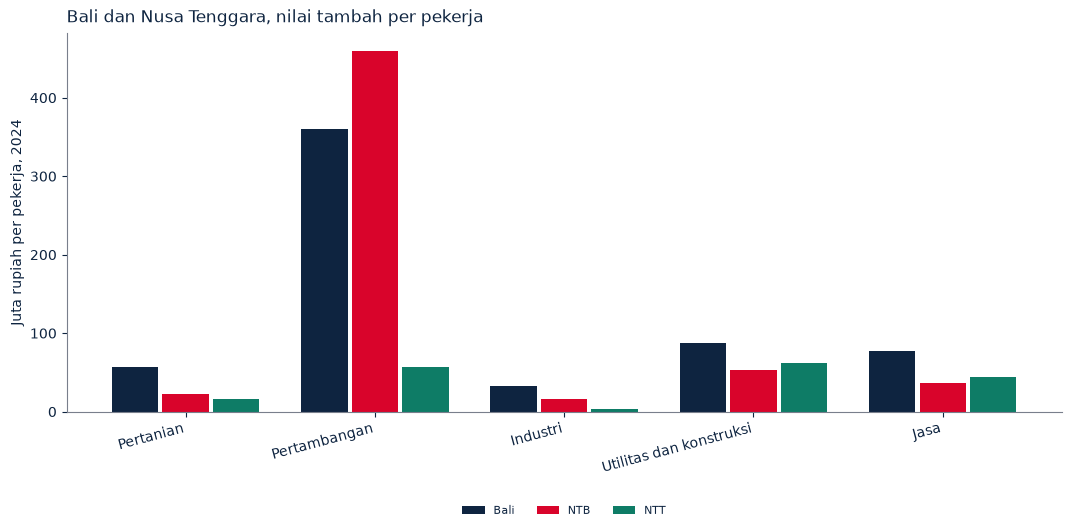

01 Data/TFP/output/tipologi/tip_W_balinusra_kerja.png


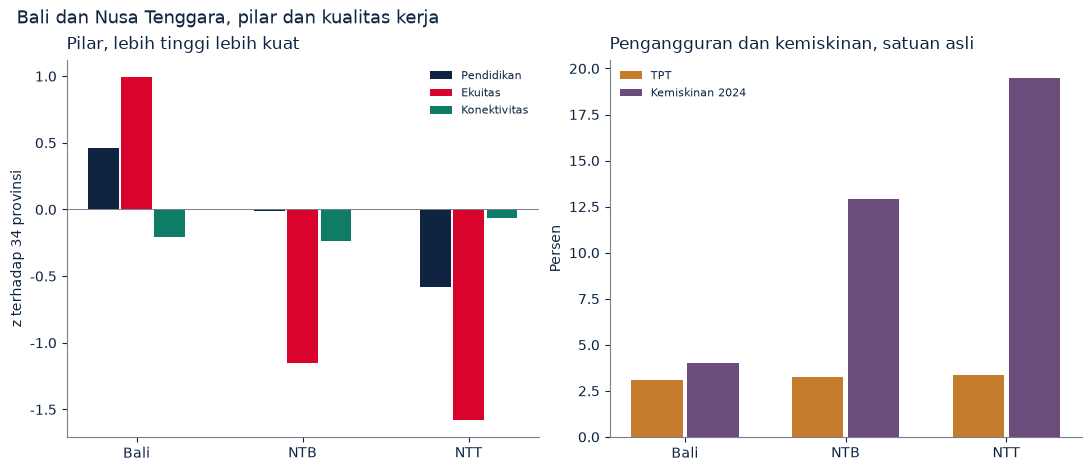

Code_Prov              DIY   Bali   NTB
kelompok                               
Akomodasi dan makan   56.4   86.3   9.8
Jasa lain            126.9  107.7  48.8
Perdagangan           24.9   32.5  28.1
Transportasi          73.6  100.7  73.9
01 Data/TFP/output/tipologi/tip_W_balinusra_jasa.png


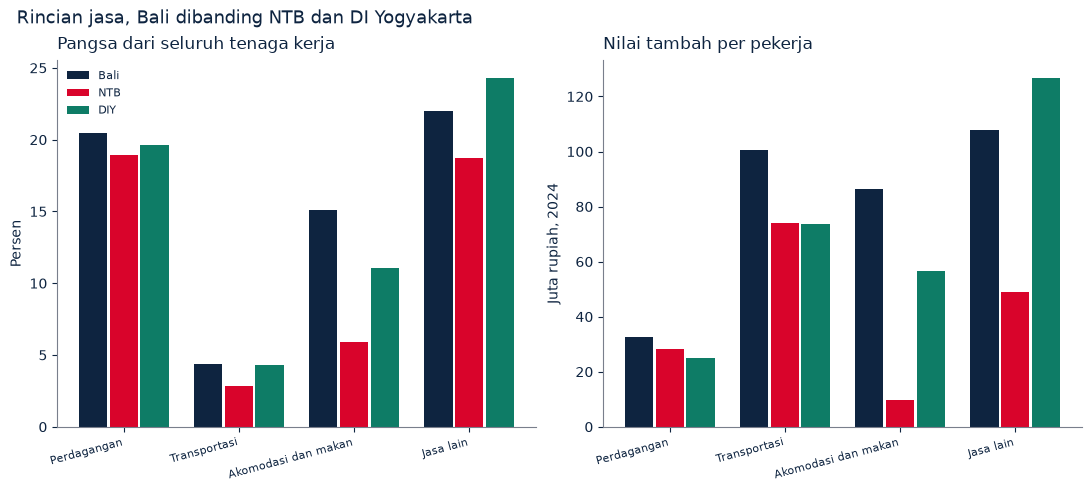

In [7]:
kode = [51, 52, 53]
print(prov.set_index("code").loc[kode, ["short", "kode_kat", "tk_tersier", "tk_primer", "tpt", "upah24", "p0_24"]].to_string())
lp_sektor(kode, "tip_W_balinusra_sektor.png", "Bali dan Nusa Tenggara, nilai tambah per pekerja")
profil_batang(kode, "tip_W_balinusra_kerja.png", "Bali dan Nusa Tenggara, pilar dan kualitas kerja")
rinci = jasa[(jasa.Year == 2024) & (jasa.Code_Prov.isin([51, 52, 34]))]
print(rinci.pivot(index="kelompok", columns="Code_Prov", values="lp").rename(columns=SHORT).round(1))
gambar_jasa([51, 52, 34], "tip_W_balinusra_jasa.png", "Rincian jasa, Bali dibanding NTB dan DI Yogyakarta")


## Maluku dan Papua

Empat provinsi. Pertanian dan pertambangan tetap pada panel sendiri, baik untuk pangsa tenaga kerja, pangsa nilai tambah, maupun nilai tambah per pekerja.


            short kode_kat       uji       rts  rank_crs      tk_A      va_B   sekolah
code                                                                                  
81         Maluku        H  memuat 1  1.060121        31  0.328449  0.023662  9.922500
82          Malut        B       IRS  3.201173        30  0.339885  0.138388  9.041250
91    Papua Barat        D  memuat 1  0.622665         3  0.334438  0.192133  7.630625
94          Papua        G  memuat 1  0.875483        10  0.683361  0.396146  6.774063
01 Data/TFP/output/tipologi/tip_W_malpap_jalur.png


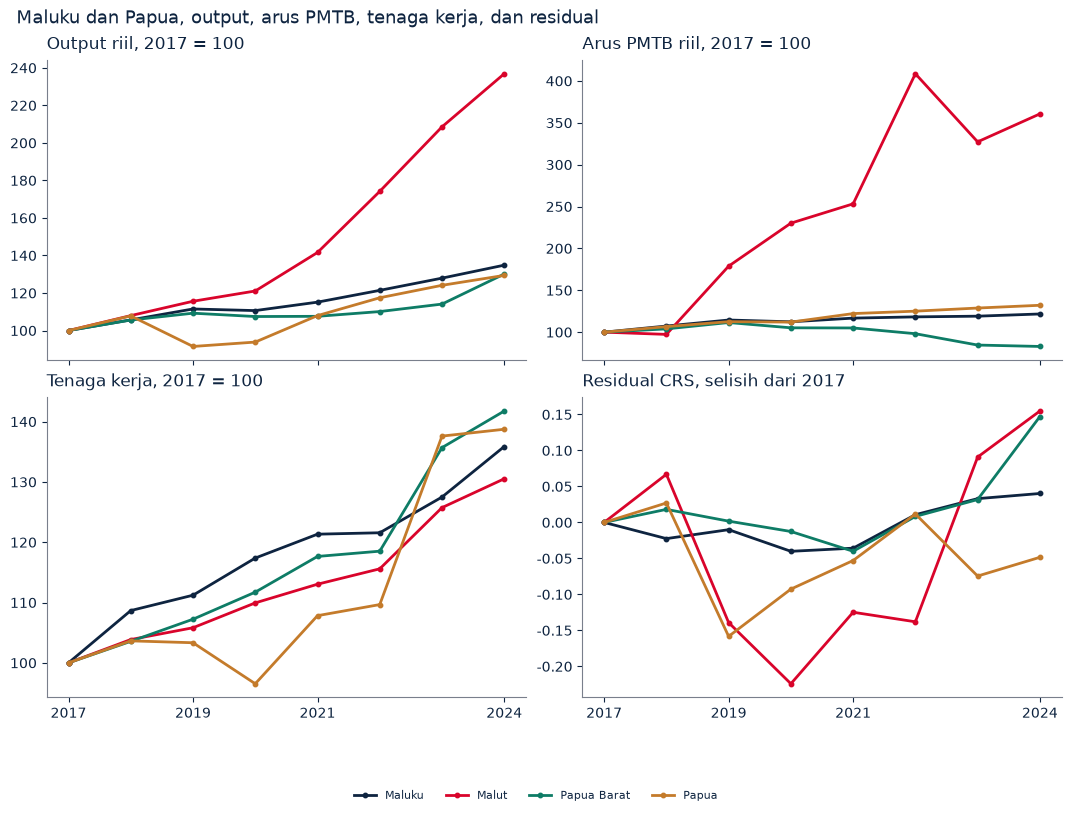

01 Data/TFP/output/tipologi/tip_W_malpap_primer.png


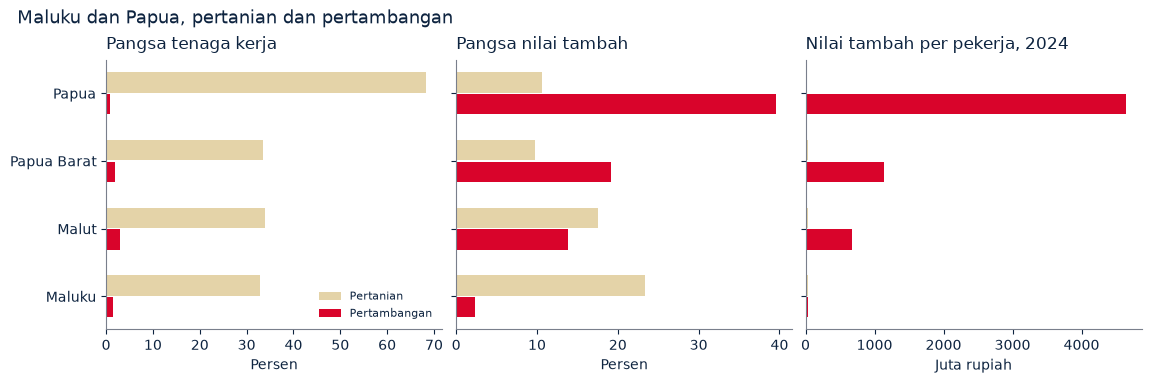

In [8]:
kode = [81, 82, 91, 94]
print(prov.set_index("code").loc[kode, ["short", "kode_kat", "uji", "rts", "rank_crs", "tk_A", "va_B", "sekolah"]].to_string())
indeks_input(kode, "tip_W_malpap_jalur.png", "Maluku dan Papua, output, arus PMTB, tenaga kerja, dan residual")
primer(kode, "tip_W_malpap_primer.png", "Maluku dan Papua, pertanian dan pertambangan")
